# Present Your Solution

This notebook summarizes the Early Spring project for the client: what we predicted, how we built the model, how well it works, and what its limits are. The full details are in the Exploration, Preparation, and Training notebooks.

## Summary

**Goal:** By March 1, predict whether May 1–10 will have early-spring planting conditions in Western Pennsylvania, so farms know whether to order seed for early planting.

**Result:** A tuned Logistic Regression model that uses January and February weather and soil data, two climate indices, and Phil's prediction. In cross-validation on the 57 training years it caught **87% of early springs** (recall 0.867), with a precision of 0.370 and an F1 score of 0.508. That is better than Phil and better than always predicting an early spring.

<mark>**TODO:**<mark> Add the test-set recall, precision, and F1 from the Final Results section below, and one sentence on whether the model meets the 5-to-1 business benchmark.


## The Problem

An **early spring** means all four planting conditions are met during May 1–10:

- soil temperature above 50°F
- minimum air temperature above 30°F
- average air temperature above 40°F
- no snow on the ground

The prediction has to be ready by **March 1**, when farms order seed, so the model can only use information available by then.

**Missing an early spring is the most costly mistake** for the farms, so the main metric is **recall** for early-spring years (the share of early springs the model catches). Precision and F1 are also reported so false alarms are not ignored. Accuracy is not used because 75% of years are not early springs, so a model that always says "no" would already be 75% accurate.

## The Data

| Source | What it contains |
|---|---|
| Client: `early_spring.csv` | Whether each year had an early spring (the target) |
| Client: `phil_pred.csv` | Punxsutawney Phil's prediction each year |
| Client: `weather.csv` | Daily air temperature, precipitation, snowfall, and snow depth (January 1 – March 1) |
| Client: `soil.csv` | Daily soil temperature and moisture (January 1 – March 1) |
| NOAA: Niño 3.4 | Monthly El Niño / La Niña index (November – January) |
| NOAA: NAO | Monthly North Atlantic Oscillation index (November – January) |

- **72 labeled years** (1947–2026, with 8 years missing from every client dataset). 25% are early springs.
- The years were split **80/20** into 57 training years and 15 test years, stratified so both sets have the same share of early springs. The test set was only used once, for the final evaluation.
- February climate index values are published after March 1, so they are not used.

In [4]:
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score, precision_score, recall_score

from preparation import build_preprocessor

train_set = pd.read_parquet("train_set.parquet")

# Monthly features before imputation and scaling, so values stay in their real units
engineered = build_preprocessor()[:4].fit_transform(train_set)

## What We Learned from the Data

No single measurement separates early-spring years from the rest; the two groups overlap heavily on every feature. The clearest signals were the long-term trend and February snow.

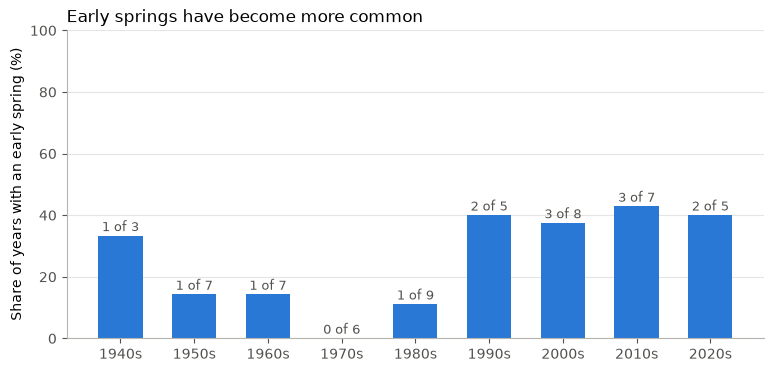

In [5]:
by_decade = (
    train_set.assign(decade=train_set["year"] // 10 * 10)
    .groupby("decade")["early_spring"]
    .agg(rate="mean", early="sum", years="count")
)

plt.figure(figsize=(9, 4))
plt.bar(by_decade.index.astype(str) + "s", by_decade["rate"] * 100)
for x, row in enumerate(by_decade.itertuples()):
    plt.text(x, row.rate * 100 + 1.5, f"{row.early} of {row.years}", ha="center")

plt.title("Early Springs by Decade")
plt.xlabel("Decade")
plt.ylabel("Share of years with an early spring (%)")
plt.ylim(0, 100)
plt.show()

**Early springs have become more common.** Before 1990, 4 of 32 training years (12.5%) were early springs. From 1990 on, 10 of 25 (40%) were, which may reflect a warming climate. Some decades have only a few years, so individual bars are noisy. The labels show how many years each bar is based on.

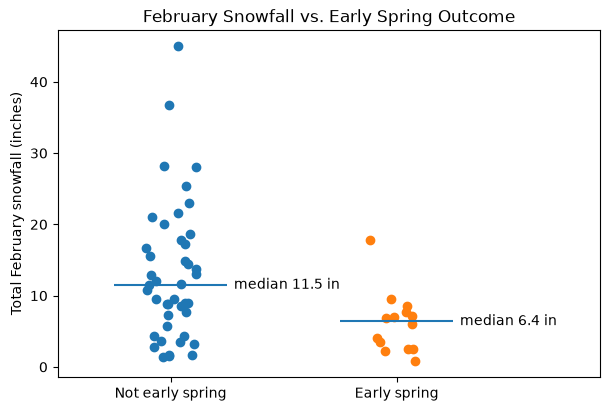

In [6]:
feb_snow = engineered["snowfall_feb_total"]
groups = {
    "Not early spring": feb_snow[~train_set["early_spring"]].dropna(),
    "Early spring": feb_snow[train_set["early_spring"]].dropna(),
}

rng = np.random.default_rng(42)
plt.figure(figsize=(7, 4.5))
for x, (label, values) in enumerate(groups.items()):
    jitter = rng.uniform(-0.12, 0.12, len(values))
    plt.scatter(x + jitter, values)
    median = values.median()
    plt.hlines(median, x - 0.25, x + 0.25)
    plt.text(x + 0.28, median, f"median {median:.1f} in", va="center")

plt.xticks(range(len(groups)), groups.keys())
plt.xlim(-0.5, 1.9)
plt.title("February Snowfall vs. Early Spring Outcome")
plt.ylabel("Total February snowfall (inches)")
plt.show()

**February snowfall was the strongest single weather signal** (correlation −0.33 with an early spring). February features were generally more useful than January ones, which makes sense because February is closer to the planting window. Even so, the two groups overlap a lot, which is why the model combines many weak signals instead of relying on one.

**Phil:** When Phil predicted an early spring, 4 of 10 training years (40%) actually met the planting conditions, compared with 10 of 47 (21%) when he predicted more winter. He is slightly better than chance, but he only predicted an early spring 10 times. His prediction also covers mid-March, not May, so he was kept as one input among many rather than the answer.

**Climate indices:** The NOAA climate indices are used in the final model, but as supporting signals: November NAO ranks 13th of 159 features, while Niño 3.4 ranks near the middle. Late-February snow, precipitation, and soil moisture carry the most weight. As in the exploration, a lower November NAO and a lower (more La Niña-like) Niño 3.4 point toward an early spring.

## Preparing the Data

The raw data has 740 columns for only 57 training years, which makes it very easy for a model to memorize the training years instead of learning general patterns. The preprocessing pipeline (`preprocessor.pkl`) turns any year's raw data into 160 model-ready features:

- **Monthly summaries:** daily values are averaged (or totaled, for precipitation and snowfall) for January and February, along with temperature spread, extremes, the share of days above freezing, and the share of snowy days.
- **The last 10 days before March 1** are kept as their own features, because they are closest to the planting window.
- **Skewed data:** precipitation, snowfall, and snow depth are mostly zeros with a few large storms, so they are log-transformed.
- **Missing values** (for example, 2001 has no January air temperatures and the climate indices start in 1950) are filled with the median or mean.
- **Scaling:** every feature is standardized, so soil moisture (around 0.47), temperatures, and climate indices are on the same scale.

Several of these choices, such as whether to average the three Niño 3.4 months, keep `year` and Phil's prediction, or select a subset of features, were tuned as hyperparameters instead of being fixed by hand.

## Models Compared

**Shortlist:** Seven untuned models were compared with 5-fold stratified cross-validation on the training set.

| Model | CV recall | CV precision | CV F1 |
|---|---:|---:|---:|
| Decision tree | 0.200 | 0.167 | 0.169 |
| Random forest | 0.067 | 0.200 | 0.100 |
| Linear SVM | 0.500 | 0.277 | 0.356 |
| RBF SVM | 0.000 | 0.000 | 0.000 |
| Neural network (MLP) | 0.067 | 0.067 | 0.067 |
| Logistic Regression | 0.300 | 0.367 | 0.320 |
| Gradient Boosting | 0.400 | 0.347 | 0.361 |

**Fine-tuning:** LinearSVC, Logistic Regression, Random Forest, and Gradient Boosting were tuned with a randomized search over 11 to 15 hyperparameters each, including 8 preprocessing options. Each search picked the settings with the best cross-validated recall.

,Recall,Precision,F1
Model,,,
LinearSVC,0.867,0.378,0.517
Logistic Regression,0.867,0.370,0.508
Gradient Boosting,0.567,0.407,0.460
Random Forest,0.533,0.348,0.382


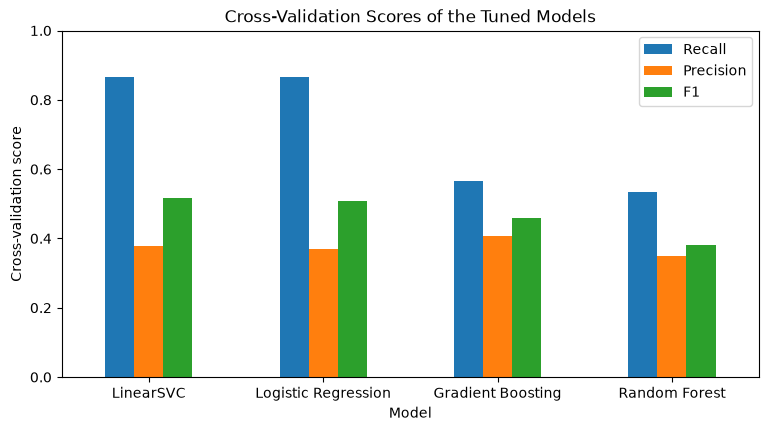

In [7]:
# Best cross-validation scores from each tuned search (Training notebook)
tuned = pd.DataFrame({
    "Model": ["LinearSVC", "Logistic Regression", "Gradient Boosting", "Random Forest"],
    "Recall": [0.867, 0.867, 0.567, 0.533],
    "Precision": [0.378, 0.370, 0.407, 0.348],
    "F1": [0.517, 0.508, 0.460, 0.382],
}).set_index("Model")

display(tuned)

tuned.plot(kind="bar", figsize=(9, 4.5), rot=0)
plt.title("Cross-Validation Scores of the Tuned Models")
plt.ylabel("Cross-validation score")
plt.ylim(0, 1)
plt.show()

LinearSVC and Logistic Regression caught the same share of early springs (recall 0.867) with nearly the same precision. The tree ensembles overfit badly: they caught nearly every early spring in the training years (training recall 0.97–1.00) but only about half in cross-validation, which is expected with only 57 years and 14 early springs.

**Logistic Regression was chosen as the final model.** Its scores are essentially tied with LinearSVC (the 0.01 difference in F1 is well within the noise for this little data), and it also gives a probability for each prediction, which made it possible to test different decision thresholds.

## Final Results on the Test Set

The final model (`model.pkl`) contains the preprocessor and the tuned Logistic Regression. It is evaluated once on the 15 test years it has never seen, and compared with two simple alternatives: always predicting an early spring, and using Phil's prediction.

In [ ]:
with open("model.pkl", "rb") as file:
    model = pickle.load(file)

test_set = pd.read_parquet("test_set.parquet")
X_test = test_set.drop(columns=["early_spring"])
y_test = test_set["early_spring"].astype(bool)

predictions = {
    "Final model": pd.Series(model.predict(X_test), index=X_test.index).astype(bool),
    "Always early spring": pd.Series(True, index=X_test.index),
    "Phil": test_set["phil_pred"].astype(bool),
}

rows = []
for name, pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[False, True]).ravel()
    rows.append({
        "Approach": name,
        "Early springs caught": f"{tp} of {tp + fn}",
        "False alarms": fp,
        "Recall": recall_score(y_test, pred, zero_division=0),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
    })

display(pd.DataFrame(rows).set_index("Approach").round(3))

ConfusionMatrixDisplay.from_predictions(
    y_test, predictions["Final model"], labels=[False, True],
    display_labels=["Not early", "Early spring"],
)
plt.title("Final Model on the 15 Test Years")
plt.show()

**TODO:** After running the cell above, describe the results in plain language:

- How many of the test set's early springs the model caught, and how many false alarms it raised.
- How it compares with Phil and with always predicting an early spring.
- How the test scores compare with the cross-validation scores, and why they can differ a lot here (the test set has only a few early springs, so each one changes recall by a large amount).

## Does the Model Meet the Business Objective?

In Frame the Problem, the minimum requirement was that the model's predictions produce a better return than the cost of planting, using the client's estimate that a harvest returns about **5 times** what is spent on seed.

<mark>**TODO:**<mark> Using the test-set confusion matrix, work out the expected return when the farms follow the model's predictions, and compare it with the 5-to-1 benchmark and with the two simple alternatives. Use the cost structure the client described (what a false alarm costs versus what a missed early spring costs).

## Limitations and Next Steps

- **Very little data.** 57 training years with 14 early springs, and 15 test years. Small changes, such as one more or one fewer correct prediction, move every score a lot.
- **Many false alarms.** To catch most early springs, the model also predicts an early spring in many years that do not have one.
- **Weak signals.** No feature strongly separates the two kinds of years. The model combines many weak signals, mostly February snow and temperature.
- **The climate is changing.** Early springs have become more common since 1990. The train/test split was random rather than by time, so the model has not been tested on training only with older years and predicting newer ones.

**Next steps:** add more years or more nearby weather stations if the client has them; try time-based validation (train on earlier years, test on later ones); and revisit the decision threshold with the client once the real costs of false alarms and missed early springs are known.